# HW10 Part 4: Does it work on new years?
**Project F1: Moodle Activity, Denis Artemjev**

This is goal 3 of our project. The rule and the models learn on the older years (2019, 2021 to 2024), and a teacher would use them on a new year. So we check how well they work on 2025 and 2026, and we look at **each year on its own**, because one good number for both years together can hide one bad year.

Our goal from HW7:
- **recall at least 0.7**: find at least 7 of 10 students who fail;
- **precision at least 1/3**: at least 1 of 3 marked students really fails.

This notebook answers **Task 3c and 3d** of HW10.

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import recall_score, precision_score

sys.path.append("..")                     # so Python can find the src folder from hw10/
from src.prepare import build_features

os.makedirs("../results/figures", exist_ok=True)   # folder for poster figures

df = build_features("../data")

train_years = [2019, 2021, 2022, 2023, 2024]
test_years = [2025, 2026]
train = df[df["year"].isin(train_years)]
test = df[df["year"].isin(test_years)]
print("train:", len(train), "students, test:", len(test), "students")

# Course format of each year, the same as in Marina's part
FORMAT = {2019: "in-person", 2021: "remote", 2022: "hybrid", 2023: "hybrid",
          2024: "hybrid", 2025: "in-person", 2026: "in-person"}
colors = {"in-person": "tab:blue", "remote": "tab:orange", "hybrid": "tab:green"}

train: 564 students, test: 279 students


In [2]:
# Helper: how good are the "at risk" marks for one group of students
def check(students, marked):
    return {"students": len(students),
            "failed": int(students["fail"].sum()),
            "marked": int(marked.sum()),
            "found": int(((marked == 1) & (students["fail"] == 1)).sum()),
            "recall": round(recall_score(students["fail"], marked), 2),
            "precision": round(precision_score(students["fail"], marked, zero_division=0), 2)}

## 1. The simple rule in every year

Ander's baseline is the rule **"active on 15 days or less before the cutoff = at risk"**. He reports one result for 2025 and 2026 together. Here we check the rule in every year. `found` is how many failed students the rule marked.

In [3]:
rows = []
for year in sorted(df["year"].unique()):
    students = df[df["year"] == year]
    marked = (students["active_days"] <= 15).astype(int)
    row = check(students, marked)
    row["year"] = str(year)
    rows.append(row)

# 2025 and 2026 together (the number Ander reports)
row = check(test, (test["active_days"] <= 15).astype(int))
row["year"] = "2025+2026"
rows.append(row)

rule_by_year = pd.DataFrame(rows).set_index("year")
rule_by_year

,students,failed,marked,found,recall,precision
year,,,,,,
2019,114,12,32,7,0.58,0.22
2021,142,21,33,16,0.76,0.48
2022,83,10,27,9,0.90,0.33
2023,106,22,24,12,0.55,0.50
2024,119,17,25,7,0.41,0.28
2025,137,28,51,18,0.64,0.35
2026,142,17,41,15,0.88,0.37
2025+2026,279,45,92,33,0.73,0.36


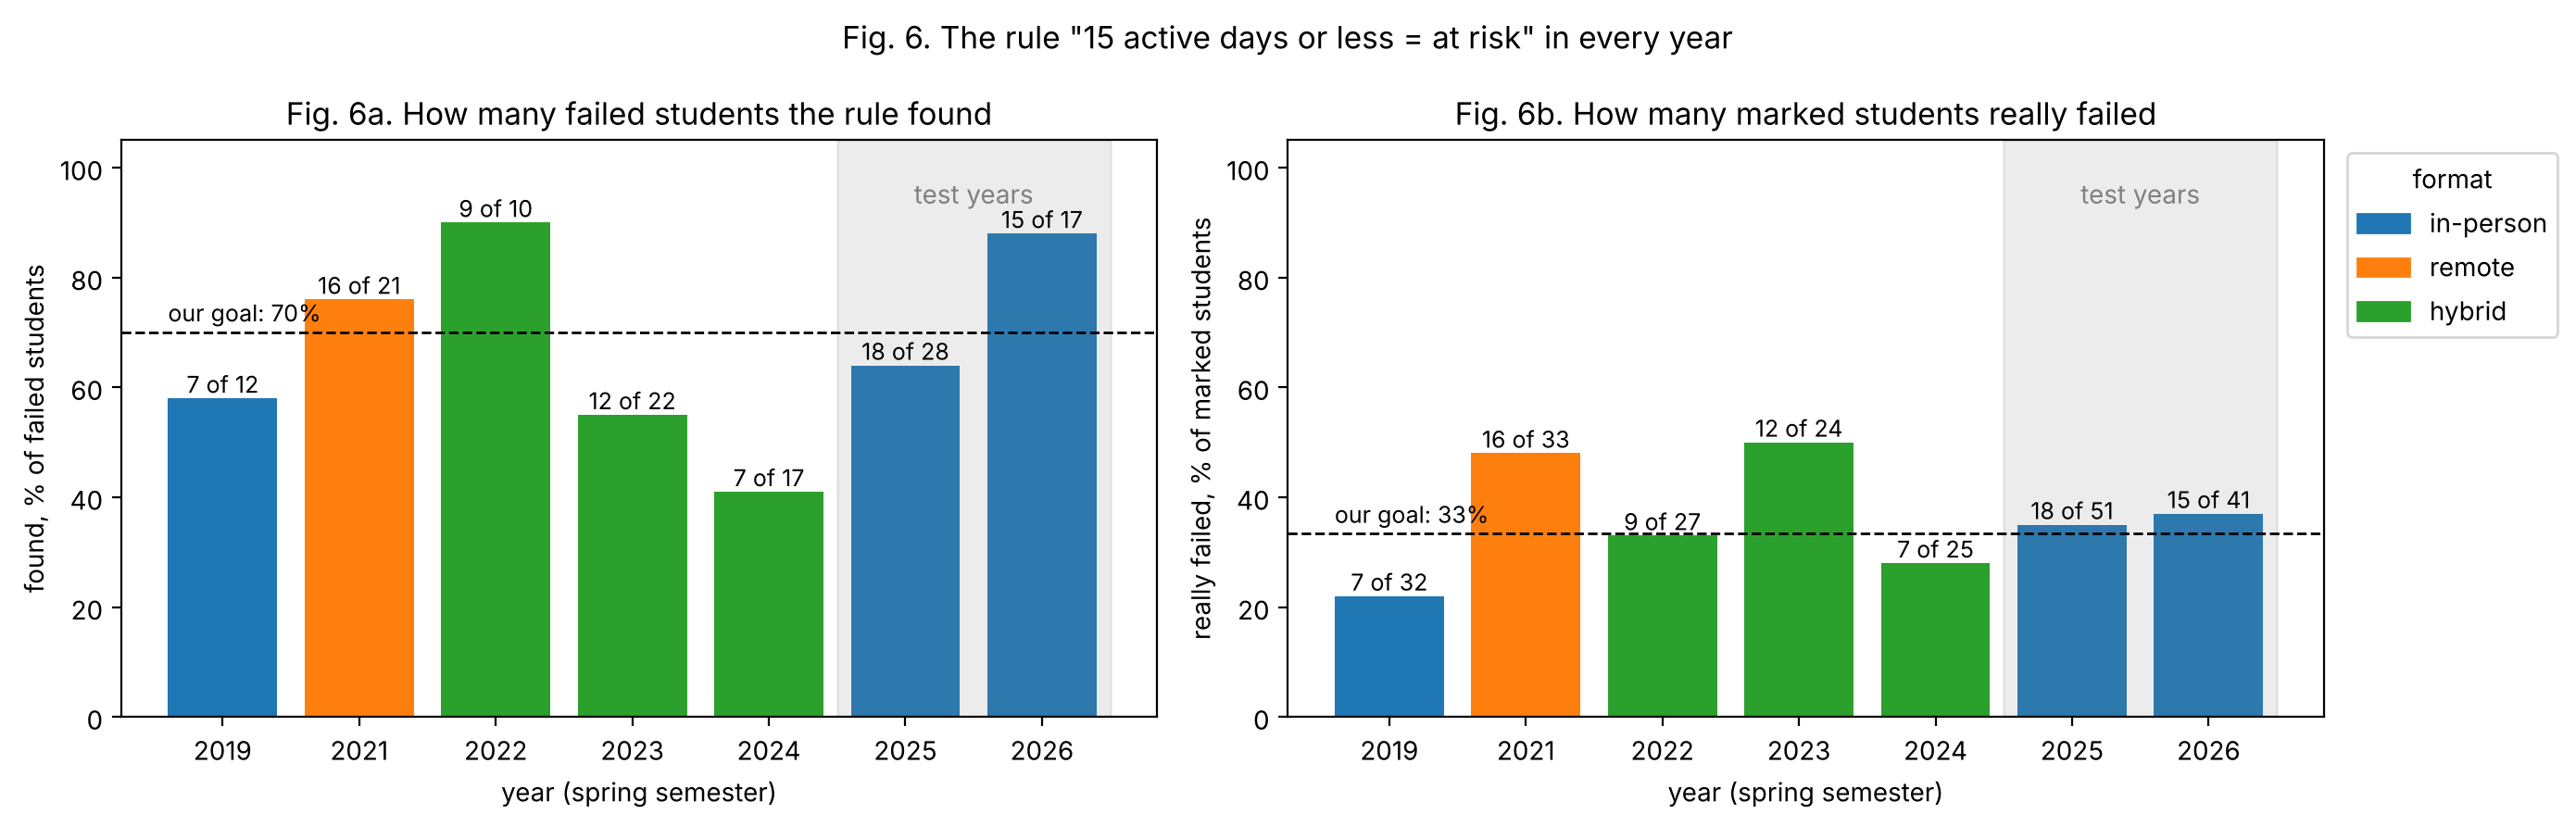

In [4]:
years = rule_by_year.drop("2025+2026")
bar_colors = [colors[FORMAT[int(y)]] for y in years.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
panels = [(axes[0], "recall", "found", "failed", 70,
           "Fig. 6a. How many failed students the rule found", "found, % of failed students"),
          (axes[1], "precision", "found", "marked", 100 / 3,
           "Fig. 6b. How many marked students really failed", "really failed, % of marked students")]

for ax, measure, top, bottom, goal, title, y_label in panels:
    bars = ax.bar(years.index, years[measure] * 100, color=bar_colors)
    # label on each bar, for example "18 of 28"
    ax.bar_label(bars, labels=[f"{a} of {b}" for a, b in zip(years[top], years[bottom])], fontsize=9)
    ax.axhline(goal, color="black", linestyle="--", linewidth=1)
    ax.text(-0.4, goal + 2, f"our goal: {goal:.0f}%", fontsize=9)
    ax.axvspan(4.5, 6.5, color="gray", alpha=0.15)                 # test years
    ax.text(5.5, 98, "test years", ha="center", va="top", color="gray")
    ax.set_ylim(0, 105)
    ax.set_title(title)
    ax.set_xlabel("year (spring semester)")
    ax.set_ylabel(y_label)

legend_items = [Patch(color=c, label=f) for f, c in colors.items()]
axes[1].legend(handles=legend_items, title="format", loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Fig. 6. The rule \"15 active days or less = at risk\" in every year")
plt.tight_layout()
plt.savefig("../results/figures/gen_fig6_rule_by_year.pdf", bbox_inches="tight")
plt.show()

For 2025 and 2026 together the rule meets our goal: it finds 33 of the 45 failed students (73%), and 36% of the marked students really fail. But the two test years are very different. In 2025 the rule finds only 18 of 28 failed students (64%), so it misses our goal. In 2026 it finds 15 of 17 (88%). Precision is about 35% in both years.

The older years jump just as much, from 41% (2024) to 90% (2022). In one year only 10 to 28 students fail, so a few students more or less change the result a lot. One number for 2025 and 2026 together looks more certain than it really is.

## 2. Compare a student with their own year

Marina found that students use Moodle less in in-person years (2025 and 2026) than in remote and hybrid years. So a fixed number like "15 days" could mark too many normal students in a new in-person year.

Her idea: use the student's **place in their own year** instead of the number of days. For example "this student is among the 30% least active students of their year". This works the same in every year, even if the whole year uses Moodle less.

To compare fairly, we choose the limit for both versions in the same way, using **only the older years**: the strictest limit that still finds at least 70% of the failed students.

In [5]:
# Place in own year: 0.3 = among the 30% least active students of that year
df["rank"] = df.groupby("year")["active_days"].rank(pct=True)
train = df[df["year"].isin(train_years)]
test = df[df["year"].isin(test_years)]

# Try limits from strict to loose, stop at the first one with recall >= 0.7 on the older years
def choose_limit(column, limits):
    for limit in limits:
        marked = (train[column] <= limit).astype(int)
        if recall_score(train["fail"], marked) >= 0.7:
            return limit

days_limit = choose_limit("active_days", range(1, 60))
rank_limit = choose_limit("rank", [i / 100 for i in range(1, 100)])
print("number of days:  at risk if active on", days_limit, "days or less")
print("place in year:   at risk if among the", round(rank_limit * 100), "% least active")

number of days:  at risk if active on 16 days or less
place in year:   at risk if among the 31 % least active


In [6]:
rows = []
for version, column, limit in [("number of days", "active_days", days_limit),
                               ("place in own year", "rank", rank_limit)]:
    for year in test_years:
        students = test[test["year"] == year]
        row = check(students, (students[column] <= limit).astype(int))
        row["year"] = year
        row["version"] = version
        rows.append(row)

compare = pd.DataFrame(rows)
compare.set_index(["year", "version"])

,,students,failed,marked,found,recall,precision
year,version,,,,,,
2025,number of days,137,28,58,19,0.68,0.33
2026,number of days,142,17,45,15,0.88,0.33
2025,place in own year,137,28,38,14,0.50,0.37
2026,place in own year,142,17,45,15,0.88,0.33


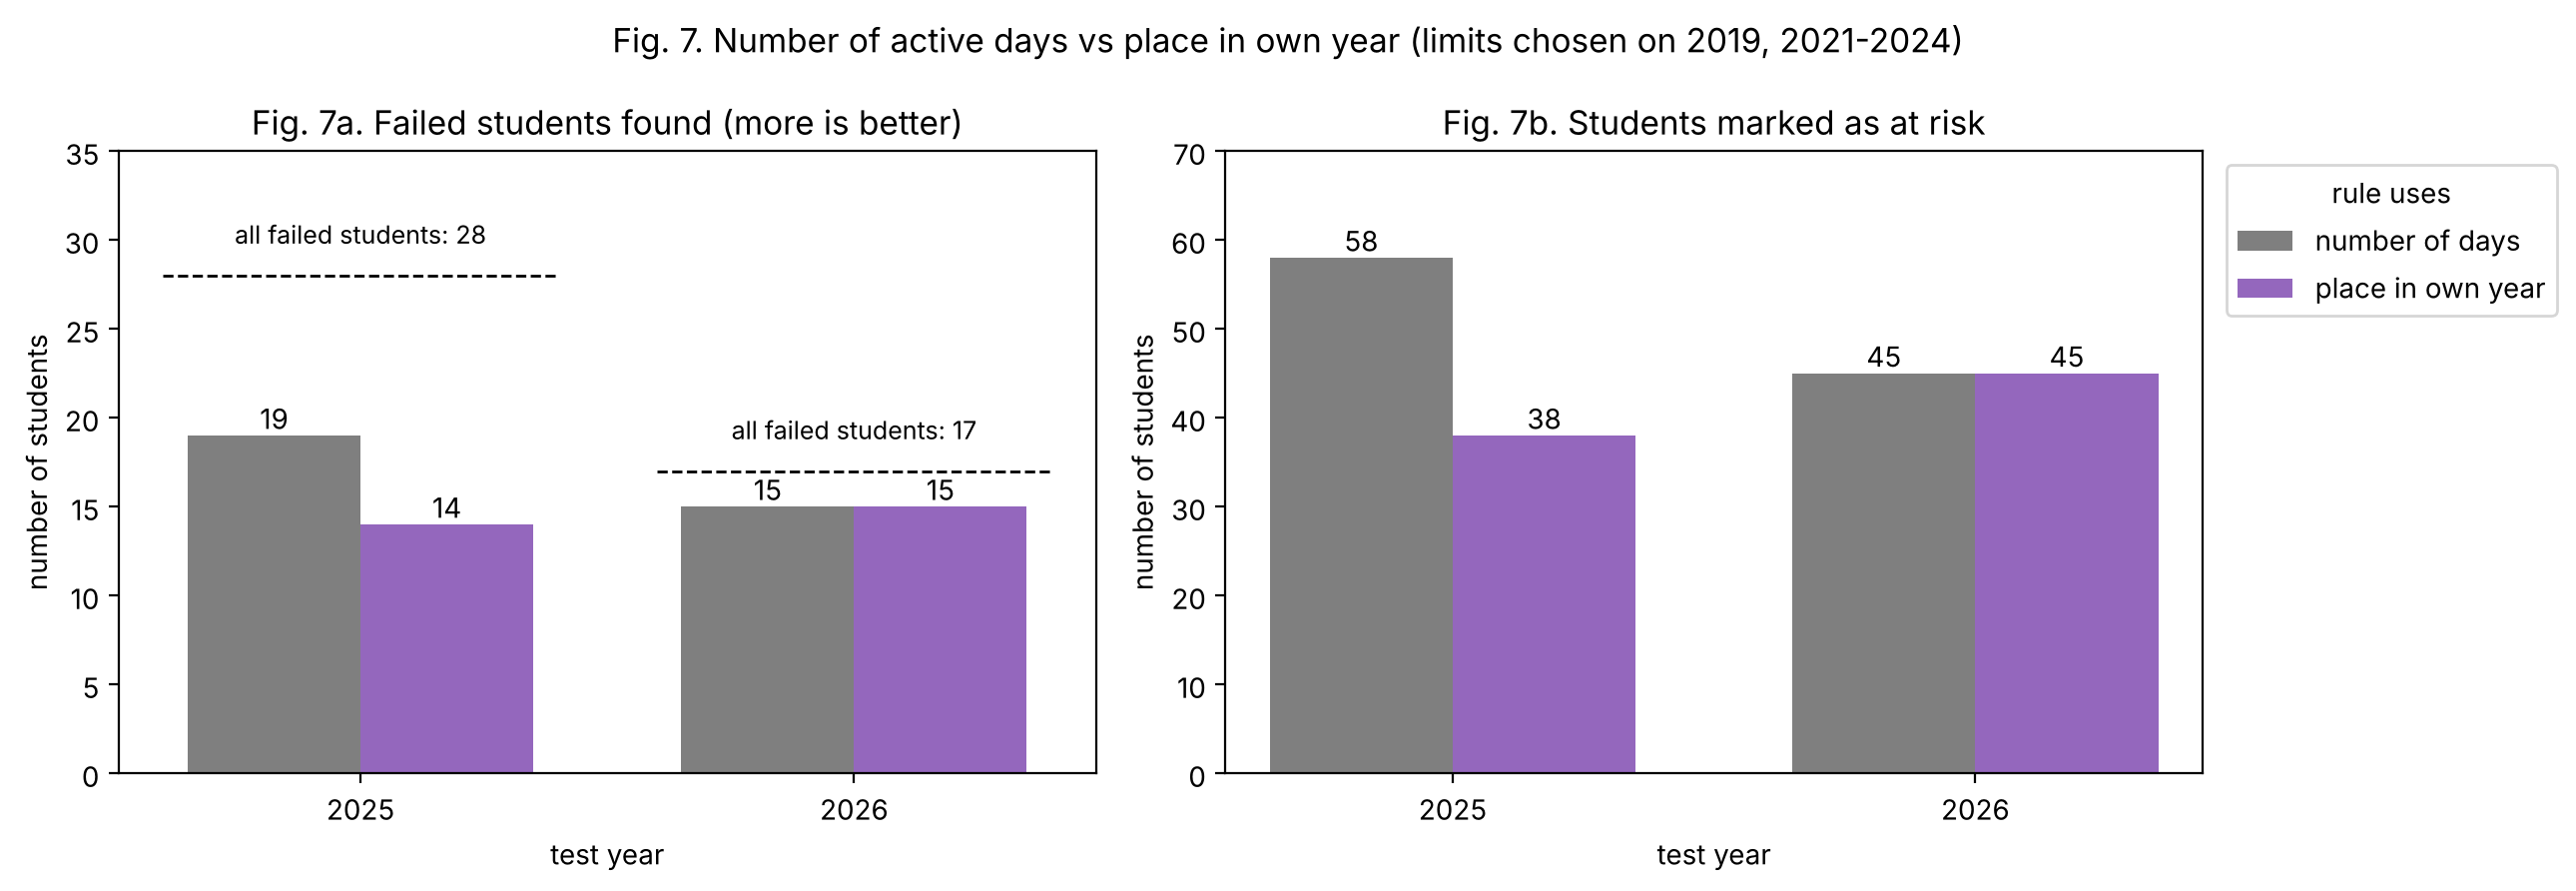

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
width = 0.35
version_colors = {"number of days": "tab:gray", "place in own year": "tab:purple"}

for i, (version, color) in enumerate(version_colors.items()):
    part = compare[compare["version"] == version]
    x = [p + (i - 0.5) * width for p in range(len(test_years))]
    bars = axes[0].bar(x, part["found"], width, color=color, label=version)
    axes[0].bar_label(bars)
    bars = axes[1].bar(x, part["marked"], width, color=color, label=version)
    axes[1].bar_label(bars)

# Dashed line: how many students failed in that year
failed = compare[compare["version"] == "number of days"]["failed"].tolist()
for p, f in enumerate(failed):
    axes[0].hlines(f, p - 0.4, p + 0.4, color="black", linestyle="--", linewidth=1)
    axes[0].text(p, f + 1.8, f"all failed students: {f}", ha="center", fontsize=9)

axes[0].set_title("Fig. 7a. Failed students found (more is better)")
axes[1].set_title("Fig. 7b. Students marked as at risk")
axes[0].set_ylim(0, 35)
axes[1].set_ylim(0, 70)
for ax in axes:
    ax.set_xticks(range(len(test_years)))
    ax.set_xticklabels(test_years)
    ax.set_xlabel("test year")
    ax.set_ylabel("number of students")
axes[1].legend(title="rule uses", loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Fig. 7. Number of active days vs place in own year (limits chosen on 2019, 2021-2024)")
plt.tight_layout()
plt.savefig("../results/figures/gen_fig7_own_year.pdf", bbox_inches="tight")
plt.show()

Comparing a student with their own year does not help. In 2025 it marks fewer students (38 instead of 58), as Marina expected, but it also finds fewer failed students: 14 instead of 19 of 28. In 2026 both versions give exactly the same result.

So the problem in 2025 is not only that students used Moodle less. In 2025 more students failed (28, which is 20% of the year), and some of them were quite active in Moodle before the cutoff. A different limit can't find them. We keep the number of active days.

## 3. Ander's final model in 2025 and 2026

<!-- TODO: add when Ander's final model is ready: same table and figure as in part 1, for 2025 and 2026 separately -->
*Will be added when the final model is ready.*

## Task 3c

The biggest threat is that the results change a lot from year to year. For 2025 and 2026 together the simple rule meets our goal, but in 2025 it finds only 64% of the failed students and in 2026 88%. In the older years it goes from 41% to 90%. In one year only 10 to 28 students fail, so a few students change the numbers a lot. We also learn on mostly remote and hybrid years and test on in-person years, when students use Moodle less.

This worries us quite a lot. Our numbers show what can happen in a new year, not a promise. A teacher should check the result again after every new year.

## Task 3d

Yes. Marina's trend analysis (step 2, data understanding) showed that students use Moodle less in in-person years. So we went back to data preparation (step 3) and tried a new feature: the student's place in their own year instead of the number of active days. It did not help: in 2025 it found fewer failed students (14 instead of 19 of 28), and in 2026 the result was the same. So we kept the original feature.

## Summary

1. **The simple rule** meets our goal for 2025 and 2026 together, but not in 2025 alone (recall 0.64).
2. **Years are very different**, because only 10 to 28 students fail in one year. This is the biggest threat to our conclusion.
3. **Comparing a student with their own year does not help**, so we keep the number of active days.
4. **Ander's final model** will be checked here in the same way when it is ready.